# Import Libraries

In [83]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report)

# Dataset



In [84]:
df = pd.read_csv("/kaggle/input/datasets/priyatak0723/credit-risk-dataset/credit_risk_dataset.csv")
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


# Exploratory Analysis

In [85]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [86]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [87]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [88]:
df.duplicated().sum()

np.int64(165)

In [89]:
df.drop_duplicates(inplace=True)

In [90]:
df.corr(numeric_only=True)

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
person_age,1.000000,0.173293,0.163001,0.050680,0.011760,-0.022698,-0.042300,0.859215
person_income,0.173293,1.000000,0.133903,0.265947,0.000878,-0.145005,-0.254472,0.117614
person_emp_length,0.163001,0.133903,1.000000,0.113183,-0.056607,-0.082817,-0.053999,0.144889
loan_amnt,0.050680,0.265947,0.113183,1.000000,0.146937,0.105736,0.572824,0.041865
loan_int_rate,0.011760,0.000878,-0.056607,0.146937,1.000000,0.335853,0.120207,0.015896
loan_status,-0.022698,-0.145005,-0.082817,0.105736,0.335853,1.000000,0.379697,-0.016498
loan_percent_income,-0.042300,-0.254472,-0.053999,0.572824,0.120207,0.379697,1.000000,-0.031457
cb_person_cred_hist_length,0.859215,0.117614,0.144889,0.041865,0.015896,-0.016498,-0.031457,1.000000


# Visualization

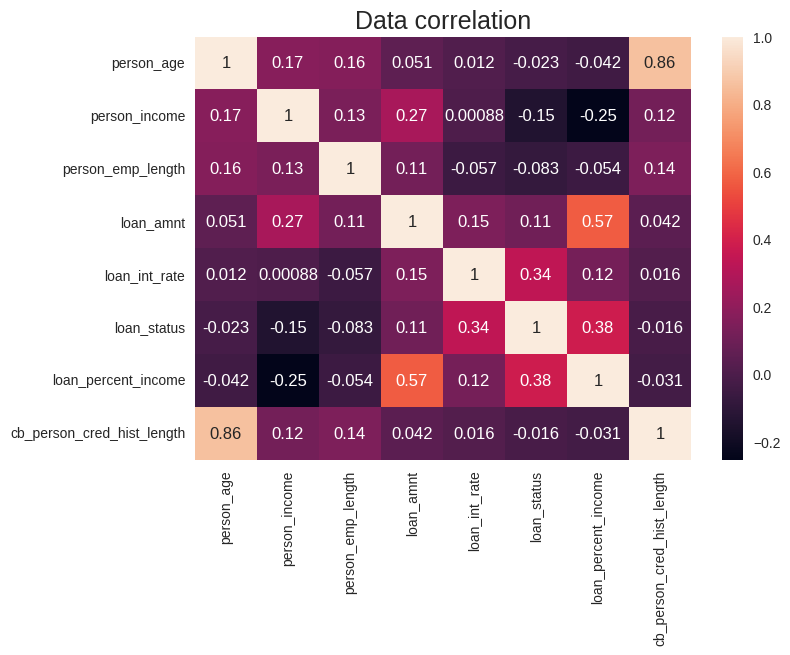

In [91]:
dataplot = sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.title('Data correlation', fontsize=18)
plt.show()

Text(0.5, 1.0, 'Loan Status')

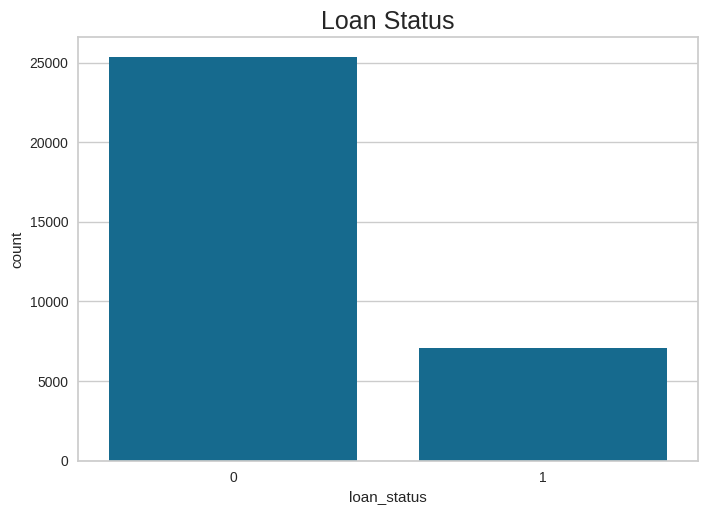

In [92]:
sns.countplot(x=df['loan_status'])
plt.title('Loan Status', fontsize=18)

Text(0.5, 1.0, 'Home ownership')

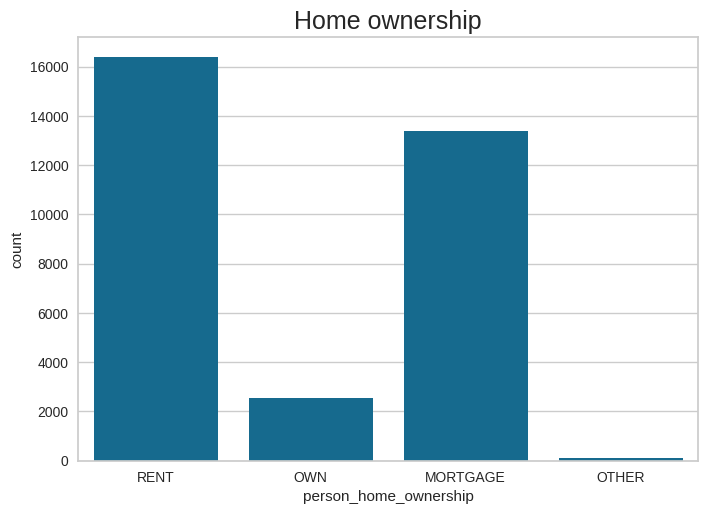

In [93]:
sns.countplot(x=df['person_home_ownership'])
plt.title('Home ownership', fontsize=18)

# Data Cleaning

In [94]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              887
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3095
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

## Finding outliers

In [95]:
df['person_age'].max()

144

Assuming individuals with age > 90 to be errors

In [96]:
df = df.loc[df['person_age'] < 90]

In [97]:
df['person_emp_length'].max()

123.0

Employment cannot be greater than the individual's age.

In [98]:
df = df.loc[df['person_emp_length'] < df['person_age'] - 15]

## Creating groups

In [99]:
df['income_group'] = pd.cut(df['person_income'], bins=
                           [0, 25000, 50000, 75000, 100000, float('inf')],
                           labels=['low', 'l-middle', 'middle', 'h-middle', 'high'])

In [100]:
df['income_group']

1             low
2             low
3          middle
4          middle
5             low
           ...   
32576      middle
32577        high
32578    h-middle
32579        high
32580    l-middle
Name: income_group, Length: 30786, dtype: category
Categories (5, object): ['low' < 'l-middle' < 'middle' < 'h-middle' < 'high']

In [101]:
df['loan_amnt_group'] = pd.cut(df['loan_amnt'], bins=
                                 [0, 10000, 15000, float('inf')],
                                 labels=['small', 'medium', 'large'])

In [102]:
df['loan_amnt_group']

1         small
2         small
3         large
4         large
5         small
          ...  
32576     small
32577     large
32578     large
32579    medium
32580     small
Name: loan_amnt_group, Length: 30786, dtype: category
Categories (3, object): ['small' < 'medium' < 'large']

In [103]:
df['loan_to_income'] = df['loan_amnt'] / df['person_income']
df['loan_to_income']

1        0.104167
2        0.572917
3        0.534351
4        0.643382
5        0.252525
           ...   
32576    0.109434
32577    0.146875
32578    0.460526
32579    0.100000
32580    0.154167
Name: loan_to_income, Length: 30786, dtype: float64

# Data Processing and Encoding

In [104]:
y_credit = df['loan_status']
X_credit = df.drop(['loan_status'], axis=1)

In [105]:
X_credit.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_default_on_file',
       'cb_person_cred_hist_length', 'income_group', 'loan_amnt_group',
       'loan_to_income'],
      dtype='object')

In [106]:
cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file', 'income_group', 'loan_amnt_group']
X_credit = pd.get_dummies(X_credit, columns=cols)

In [107]:
X_credit.head(1)

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,loan_to_income,person_home_ownership_MORTGAGE,person_home_ownership_OTHER,...,cb_person_default_on_file_N,cb_person_default_on_file_Y,income_group_low,income_group_l-middle,income_group_middle,income_group_h-middle,income_group_high,loan_amnt_group_small,loan_amnt_group_medium,loan_amnt_group_large
1,21,9600,5.0,1000,11.14,0.1,2,0.104167,False,False,...,True,False,True,False,False,False,False,True,False,False


In [108]:
X_train, X_test, y_train, y_test = train_test_split(X_credit, y_credit, test_size= 0.2, stratify=y_credit, random_state=42)

# MISSING VALUES

In [109]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='mean')
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

# SCALING

In [110]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [111]:
X_train.shape, y_train.shape

((24628, 35), (24628,))

# OVERSAMPLING

In [112]:
from imblearn.over_sampling import RandomOverSampler

oversampler = RandomOverSampler(sampling_strategy='minority', random_state=42)
X_train, y_train = oversampler.fit_resample(X_train, y_train)

# Models

# Naive Bayes

In [113]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report)

naive_bayer = GaussianNB(var_smoothing=1e-5)
naive_bayer.fit(X_train, y_train)
predict_NB = naive_bayer.predict(X_test)

print("===== Naive Bayes =====")
print("Accuracy :", accuracy_score(y_test, predict_NB))
print("Precision:", precision_score(y_test, predict_NB))
print("Recall   :", recall_score(y_test, predict_NB))
print("F1 Score :", f1_score(y_test, predict_NB))
print("ROC-AUC  :", roc_auc_score(y_test, naive_bayer.predict_proba(X_test)[:, 1]))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predict_NB))

print("\nClassification Report:")
print(classification_report(y_test, predict_NB))

===== Naive Bayes =====
Accuracy : 0.8462163039948035
Precision: 0.7037037037037037
Recall   : 0.49924924924924924
F1 Score : 0.5841018884497146
ROC-AUC  : 0.8673503849892162

Confusion Matrix:
[[4546  280]
 [ 667  665]]

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.94      0.91      4826
           1       0.70      0.50      0.58      1332

    accuracy                           0.85      6158
   macro avg       0.79      0.72      0.74      6158
weighted avg       0.84      0.85      0.84      6158



# Decision Tree

In [114]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(criterion='entropy', max_depth=None, max_features=None, min_samples_leaf=1, min_samples_split=2, random_state=0)
decision_tree.fit(X_train, y_train)
predict_decision_tree = decision_tree.predict(X_test)

print("===== Decision Tree =====")
print("Accuracy :", accuracy_score(y_test, predict_decision_tree))
print("Precision:", precision_score(y_test, predict_decision_tree))
print("Recall   :", recall_score(y_test, predict_decision_tree))
print("F1 Score :", f1_score(y_test, predict_decision_tree))
print("ROC-AUC  :", roc_auc_score(y_test, decision_tree.predict_proba(X_test)[:, 1]))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predict_decision_tree))

print("\nClassification Report:")
print(classification_report(y_test, predict_decision_tree))

===== Decision Tree =====
Accuracy : 0.8981812276713218
Precision: 0.7541456380677721
Recall   : 0.7852852852852853
F1 Score : 0.769400514895182
ROC-AUC  : 0.8573131772468696

Confusion Matrix:
[[4485  341]
 [ 286 1046]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.93      0.93      4826
           1       0.75      0.79      0.77      1332

    accuracy                           0.90      6158
   macro avg       0.85      0.86      0.85      6158
weighted avg       0.90      0.90      0.90      6158



# Random Forest

In [115]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(n_estimators=200, criterion='entropy', random_state=0)
random_forest.fit(X_train, y_train)
predict_random_forest = random_forest.predict(X_test)

print("===== Random Forest =====")
print("Accuracy :", accuracy_score(y_test, predict_random_forest))
print("Precision:", precision_score(y_test, predict_random_forest))
print("Recall   :", recall_score(y_test, predict_random_forest))
print("F1 Score :", f1_score(y_test, predict_random_forest))
print("ROC-AUC  :", roc_auc_score(y_test, random_forest.predict_proba(X_test)[:, 1]))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predict_random_forest))

print("\nClassification Report:")
print(classification_report(y_test, predict_random_forest))

===== Random Forest =====
Accuracy : 0.936342968496265
Precision: 0.9351851851851852
Recall   : 0.7582582582582582
F1 Score : 0.8374792703150912
ROC-AUC  : 0.9375190565617421

Confusion Matrix:
[[4756   70]
 [ 322 1010]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.99      0.96      4826
           1       0.94      0.76      0.84      1332

    accuracy                           0.94      6158
   macro avg       0.94      0.87      0.90      6158
weighted avg       0.94      0.94      0.93      6158



# Nearest Neighbors

In [116]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=20)
knn.fit(X_train, y_train)
predict_knn = knn.predict(X_test)

print("===== KNN =====")
print("Accuracy :", accuracy_score(y_test, predict_knn))
print("Precision:", precision_score(y_test, predict_knn))
print("Recall   :", recall_score(y_test, predict_knn))
print("F1 Score :", f1_score(y_test, predict_knn))
print("ROC-AUC  :", roc_auc_score(y_test, knn.predict_proba(X_test)[:, 1]))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predict_knn))

print("\nClassification Report:")
print(classification_report(y_test, predict_knn))

===== KNN =====
Accuracy : 0.8262422864566418
Precision: 0.571584699453552
Recall   : 0.7852852852852853
F1 Score : 0.661606578115117
ROC-AUC  : 0.8911016279437332

Confusion Matrix:
[[4042  784]
 [ 286 1046]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.84      0.88      4826
           1       0.57      0.79      0.66      1332

    accuracy                           0.83      6158
   macro avg       0.75      0.81      0.77      6158
weighted avg       0.86      0.83      0.84      6158



# Logistic regression

In [117]:
from sklearn.linear_model import LogisticRegression

logistic = LogisticRegression(C=100, max_iter=1000, penalty='l2', solver='liblinear', random_state=0)
logistic.fit(X_train, y_train)
predict_logistic = logistic.predict(X_test)

print("===== Logistic Regression =====")
print("Accuracy :", accuracy_score(y_test, predict_logistic))
print("Precision:", precision_score(y_test, predict_logistic))
print("Recall   :", recall_score(y_test, predict_logistic))
print("F1 Score :", f1_score(y_test, predict_logistic))
print("ROC-AUC  :", roc_auc_score(y_test, logistic.predict_proba(X_test)[:, 1]))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predict_logistic))

print("\nClassification Report:")
print(classification_report(y_test, predict_logistic))

===== Logistic Regression =====
Accuracy : 0.82656706722962
Precision: 0.5694736842105264
Recall   : 0.8123123123123123
F1 Score : 0.6695544554455446
ROC-AUC  : 0.8877405171437496

Confusion Matrix:
[[4008  818]
 [ 250 1082]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.83      0.88      4826
           1       0.57      0.81      0.67      1332

    accuracy                           0.83      6158
   macro avg       0.76      0.82      0.78      6158
weighted avg       0.86      0.83      0.84      6158



# SVM

In [118]:
from sklearn.svm import SVC

svm = SVC(kernel='rbf', random_state=1, C=2)
svm.fit(X_train, y_train)
predict_svm = svm.predict(X_test)

print("===== SVM =====")
print("Accuracy :", accuracy_score(y_test, predict_svm))
print("Precision:", precision_score(y_test, predict_svm))
print("Recall   :", recall_score(y_test, predict_svm))
print("F1 Score :", f1_score(y_test, predict_svm))
print("ROC-AUC  :", roc_auc_score(y_test, svm.decision_function(X_test)))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predict_svm))

print("\nClassification Report:")
print(classification_report(y_test, predict_svm))

===== SVM =====
Accuracy : 0.8873010717765508
Precision: 0.7206085753803596
Recall   : 0.7822822822822822
F1 Score : 0.750179985601152
ROC-AUC  : 0.9120263549915436

Confusion Matrix:
[[4422  404]
 [ 290 1042]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.92      0.93      4826
           1       0.72      0.78      0.75      1332

    accuracy                           0.89      6158
   macro avg       0.83      0.85      0.84      6158
weighted avg       0.89      0.89      0.89      6158



# Neural Network

In [119]:
from sklearn.neural_network import MLPClassifier

neural_network = MLPClassifier(max_iter=240, tol=0.0000100, random_state=0)
neural_network.fit(X_train, y_train)
predict_neural_network = neural_network.predict(X_test)

print("===== Neural Network =====")
print("Accuracy :", accuracy_score(y_test, predict_neural_network))
print("Precision:", precision_score(y_test, predict_neural_network))
print("Recall   :", recall_score(y_test, predict_neural_network))
print("F1 Score :", f1_score(y_test, predict_neural_network))
print("ROC-AUC  :", roc_auc_score(y_test, neural_network.predict_proba(X_test)[:, 1]))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predict_neural_network))

print("\nClassification Report:")
print(classification_report(y_test, predict_neural_network))

===== Neural Network =====
Accuracy : 0.868626177330302
Precision: 0.671026814911707
Recall   : 0.7702702702702703
F1 Score : 0.717231737154841
ROC-AUC  : 0.9074924489346371

Confusion Matrix:
[[4323  503]
 [ 306 1026]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.90      0.91      4826
           1       0.67      0.77      0.72      1332

    accuracy                           0.87      6158
   macro avg       0.80      0.83      0.82      6158
weighted avg       0.88      0.87      0.87      6158



/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (240) reached and the optimization hasn't converged yet.
  warnings.warn(


# GRADIENT BOOSTING

In [120]:
from sklearn.ensemble import GradientBoostingClassifier

gradient_boosting = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=0)
gradient_boosting.fit(X_train, y_train)
predict_gradient_boosting = gradient_boosting.predict(X_test)

print("===== Gradient Boosting =====")
print("Accuracy :", accuracy_score(y_test, predict_gradient_boosting))
print("Precision:", precision_score(y_test, predict_gradient_boosting))
print("Recall   :", recall_score(y_test, predict_gradient_boosting))
print("F1 Score :", f1_score(y_test, predict_gradient_boosting))
print("ROC-AUC  :", roc_auc_score(y_test, gradient_boosting.predict_proba(X_test)[:, 1]))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predict_gradient_boosting))

print("\nClassification Report:")
print(classification_report(y_test, predict_gradient_boosting))

===== Gradient Boosting =====
Accuracy : 0.8890873660279311
Precision: 0.7197020988490183
Recall   : 0.7980480480480481
F1 Score : 0.7568529725881097
ROC-AUC  : 0.9333172791523393

Confusion Matrix:
[[4412  414]
 [ 269 1063]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.91      0.93      4826
           1       0.72      0.80      0.76      1332

    accuracy                           0.89      6158
   macro avg       0.83      0.86      0.84      6158
weighted avg       0.89      0.89      0.89      6158



# XGBOOST

In [121]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(subsample=0.8, reg_lambda=1, reg_alpha=1, n_estimators=300, min_child_weight=5, max_depth=8, learning_rate=0.1,
                          gamma=0, colsample_bytree=0.9, random_state=0, eval_metric='logloss')
xgb_model.fit(X_train, y_train)
predict_xgb = xgb_model.predict(X_test)

print("===== XGBoost =====")
print("Accuracy :", accuracy_score(y_test, predict_xgb))
print("Precision:", precision_score(y_test, predict_xgb))
print("Recall   :", recall_score(y_test, predict_xgb))
print("F1 Score :", f1_score(y_test, predict_xgb))
print("ROC-AUC  :", roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:, 1]))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predict_xgb))

print("\nClassification Report:")
print(classification_report(y_test, predict_xgb))

===== XGBoost =====
Accuracy : 0.9303345241961676
Precision: 0.8728323699421965
Recall   : 0.7935435435435435
F1 Score : 0.8313016122689737
ROC-AUC  : 0.9500008711571082

Confusion Matrix:
[[4672  154]
 [ 275 1057]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.97      0.96      4826
           1       0.87      0.79      0.83      1332

    accuracy                           0.93      6158
   macro avg       0.91      0.88      0.89      6158
weighted avg       0.93      0.93      0.93      6158



# MODEL COMPARISON

In [122]:
results = {
    'Naive Bayes': {
        'Accuracy': accuracy_score(y_test, predict_NB),
        'Precision': precision_score(y_test, predict_NB),
        'Recall': recall_score(y_test, predict_NB),
        'F1 Score': f1_score(y_test, predict_NB),
        'ROC-AUC': roc_auc_score(y_test, naive_bayer.predict_proba(X_test)[:, 1])
    },
    'Decision Tree': {
        'Accuracy': accuracy_score(y_test, predict_decision_tree),
        'Precision': precision_score(y_test, predict_decision_tree),
        'Recall': recall_score(y_test, predict_decision_tree),
        'F1 Score': f1_score(y_test, predict_decision_tree),
        'ROC-AUC': roc_auc_score(y_test, decision_tree.predict_proba(X_test)[:, 1])
    },
    'Random Forest': {
        'Accuracy': accuracy_score(y_test, predict_random_forest),
        'Precision': precision_score(y_test, predict_random_forest),
        'Recall': recall_score(y_test, predict_random_forest),
        'F1 Score': f1_score(y_test, predict_random_forest),
        'ROC-AUC': roc_auc_score(y_test, random_forest.predict_proba(X_test)[:, 1])
    },
    'K-Nearest Neighbors': {
        'Accuracy': accuracy_score(y_test, predict_knn),
        'Precision': precision_score(y_test, predict_knn),
        'Recall': recall_score(y_test, predict_knn),
        'F1 Score': f1_score(y_test, predict_knn),
        'ROC-AUC': roc_auc_score(y_test, knn.predict_proba(X_test)[:, 1])
    },
    'Logistic Regression': {
        'Accuracy': accuracy_score(y_test, predict_logistic),
        'Precision': precision_score(y_test, predict_logistic),
        'Recall': recall_score(y_test, predict_logistic),
        'F1 Score': f1_score(y_test, predict_logistic),
        'ROC-AUC': roc_auc_score(y_test, logistic.predict_proba(X_test)[:, 1])
    },
    'Support Vector Machine': {
        'Accuracy': accuracy_score(y_test, predict_svm),
        'Precision': precision_score(y_test, predict_svm),
        'Recall': recall_score(y_test, predict_svm),
        'F1 Score': f1_score(y_test, predict_svm),
        'ROC-AUC': roc_auc_score(y_test, svm.decision_function(X_test))
    },
    'Neural Network': {
        'Accuracy': accuracy_score(y_test, predict_neural_network),
        'Precision': precision_score(y_test, predict_neural_network),
        'Recall': recall_score(y_test, predict_neural_network),
        'F1 Score': f1_score(y_test, predict_neural_network),
        'ROC-AUC': roc_auc_score(y_test, neural_network.predict_proba(X_test)[:, 1])
    },
    'Gradient Boosting': {
        'Accuracy': accuracy_score(y_test, predict_gradient_boosting),
        'Precision': precision_score(y_test, predict_gradient_boosting),
        'Recall': recall_score(y_test, predict_gradient_boosting),
        'F1 Score': f1_score(y_test, predict_gradient_boosting),
        'ROC-AUC': roc_auc_score(y_test, gradient_boosting.predict_proba(X_test)[:, 1])
    },
    'XGBoost': {
        'Accuracy': accuracy_score(y_test, predict_xgb),
        'Precision': precision_score(y_test, predict_xgb),
        'Recall': recall_score(y_test, predict_xgb),
        'F1 Score': f1_score(y_test, predict_xgb),
        'ROC-AUC': roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:, 1])
    }
}

results_df = pd.DataFrame(results).T
display(results_df.sort_values(by='F1 Score', ascending=False))

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Random Forest,0.936343,0.935185,0.758258,0.837479,0.937519
XGBoost,0.930335,0.872832,0.793544,0.831302,0.950001
Decision Tree,0.898181,0.754146,0.785285,0.769401,0.857313
Gradient Boosting,0.889087,0.719702,0.798048,0.756853,0.933317
Support Vector Machine,0.887301,0.720609,0.782282,0.750180,0.912026
Neural Network,0.868626,0.671027,0.770270,0.717232,0.907492
Logistic Regression,0.826567,0.569474,0.812312,0.669554,0.887741
K-Nearest Neighbors,0.826242,0.571585,0.785285,0.661607,0.891102
Naive Bayes,0.846216,0.703704,0.499249,0.584102,0.867350
